In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/laptop_price.csv', encoding='latin-1')
df

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


In [ ]:
df.head()

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Price_Category
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69,High
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94,Medium
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00,Low
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45,High
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60,High


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1303
Number of columns: 13


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


In [ ]:
df.isnull().sum()

,0
laptop_ID,0
Company,0
Product,0
TypeName,0
Inches,0
ScreenResolution,0
Cpu,0
Ram,0
Memory,0
Gpu,0


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [ ]:
df['Price_Category'] = pd.qcut(
    df['Price_euros'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print(df[['Price_euros', 'Price_Category']].head(10))

   Price_euros Price_Category
0      1339.69           High
1       898.94         Medium
2       575.00            Low
3      2537.45           High
4      1803.60           High
5       400.00            Low
6      2139.97           High
7      1158.70         Medium
8      1495.00           High
9       770.00         Medium


In [ ]:
print(df['Price_Category'].value_counts())

Price_Category
High      435
Low       434
Medium    434
Name: count, dtype: int64


In [ ]:
print("Duplicates before removal:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)

Duplicates before removal: 0
Duplicates after removal: 0
Updated dataset shape: (1303, 14)


In [ ]:
print(df.isnull().sum())

laptop_ID           0
Company             0
Product             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price_euros         0
Price_Category      0
dtype: int64


In [ ]:
for col in df.columns:
    if df[col].dtype == 'object' or isinstance(df[col].dtype, pd.CategoricalDtype):
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("Missing values handled successfully!")

Missing values handled successfully!


In [ ]:
df['Ram'] = df['Ram'].str.replace('GB', '', regex=False).astype(float)

df['Weight'] = df['Weight'].str.replace('kg', '', regex=False).astype(float)

print(df[['Ram', 'Weight']].head())

    Ram  Weight
0   8.0    1.37
1   8.0    1.34
2   8.0    1.86
3  16.0    1.83
4   8.0    1.37


In [ ]:
df = df.drop(
    columns=['laptop_ID', 'Product', 'Price_euros']
)

print("Unnecessary columns removed!")
print(df.head())

Unnecessary columns removed!
  Company   TypeName  Inches                    ScreenResolution  \
0   Apple  Ultrabook    13.3  IPS Panel Retina Display 2560x1600   
1   Apple  Ultrabook    13.3                            1440x900   
2      HP   Notebook    15.6                   Full HD 1920x1080   
3   Apple  Ultrabook    15.4  IPS Panel Retina Display 2880x1800   
4   Apple  Ultrabook    13.3  IPS Panel Retina Display 2560x1600   

                          Cpu   Ram               Memory  \
0        Intel Core i5 2.3GHz   8.0            128GB SSD   
1        Intel Core i5 1.8GHz   8.0  128GB Flash Storage   
2  Intel Core i5 7200U 2.5GHz   8.0            256GB SSD   
3        Intel Core i7 2.7GHz  16.0            512GB SSD   
4        Intel Core i5 3.1GHz   8.0            256GB SSD   

                            Gpu  OpSys  Weight Price_Category  
0  Intel Iris Plus Graphics 640  macOS    1.37           High  
1        Intel HD Graphics 6000  macOS    1.34         Medium  
2        

In [ ]:
X = df.drop('Price_Category', axis=1)

y = df['Price_Category']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1303, 10)
Target shape: (1303,)


In [ ]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Categorical encoding completed!")
print("Encoded dataset shape:", X.shape)

X.head()

Categorical encoding completed!
Encoded dataset shape: (1303, 337)


,Inches,Ram,Weight,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,...,Gpu_Nvidia Quadro M620,Gpu_Nvidia Quadro M620M,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,8.0,1.37,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,13.3,8.0,1.34,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,15.6,8.0,1.86,0,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
3,15.4,16.0,1.83,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,13.3,8.0,1.37,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target distribution:")
print(y_train.value_counts())

Training data: (1042, 337)
Testing data: (261, 337)
Training target distribution:
Price_Category
High      348
Low       347
Medium    347
Name: count, dtype: int64


In [ ]:
eda_df = pd.read_csv('/content/laptop_price.csv', encoding='latin1')

# Convert RAM and Weight to numeric
eda_df['Ram'] = eda_df['Ram'].str.replace(
    'GB', '', regex=False
).astype(float)

eda_df['Weight'] = eda_df['Weight'].str.replace(
    'kg', '', regex=False
).astype(float)

# Create price category
eda_df['Price_Category'] = pd.qcut(
    eda_df['Price_euros'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print("EDA dataset loaded successfully!")
eda_df.head()

EDA dataset loaded successfully!


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Price_Category
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8.0,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,High
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8.0,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,Medium
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8.0,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,Low
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16.0,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,High
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8.0,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,High


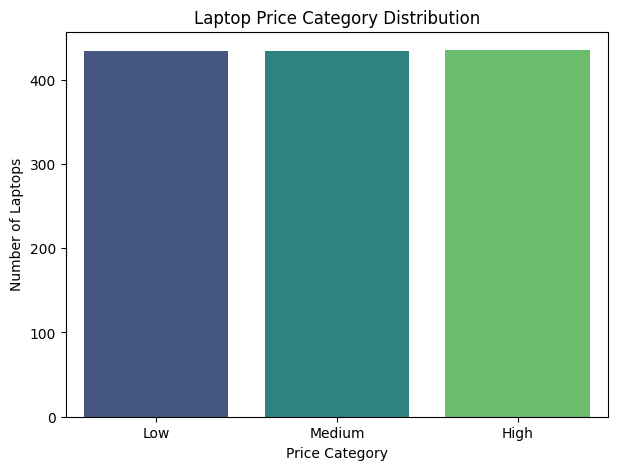

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_df,
    x='Price_Category',
    hue='Price_Category',
    palette='viridis',
    legend=False
)

plt.title('Laptop Price Category Distribution')
plt.xlabel('Price Category')
plt.ylabel('Number of Laptops')
plt.show()

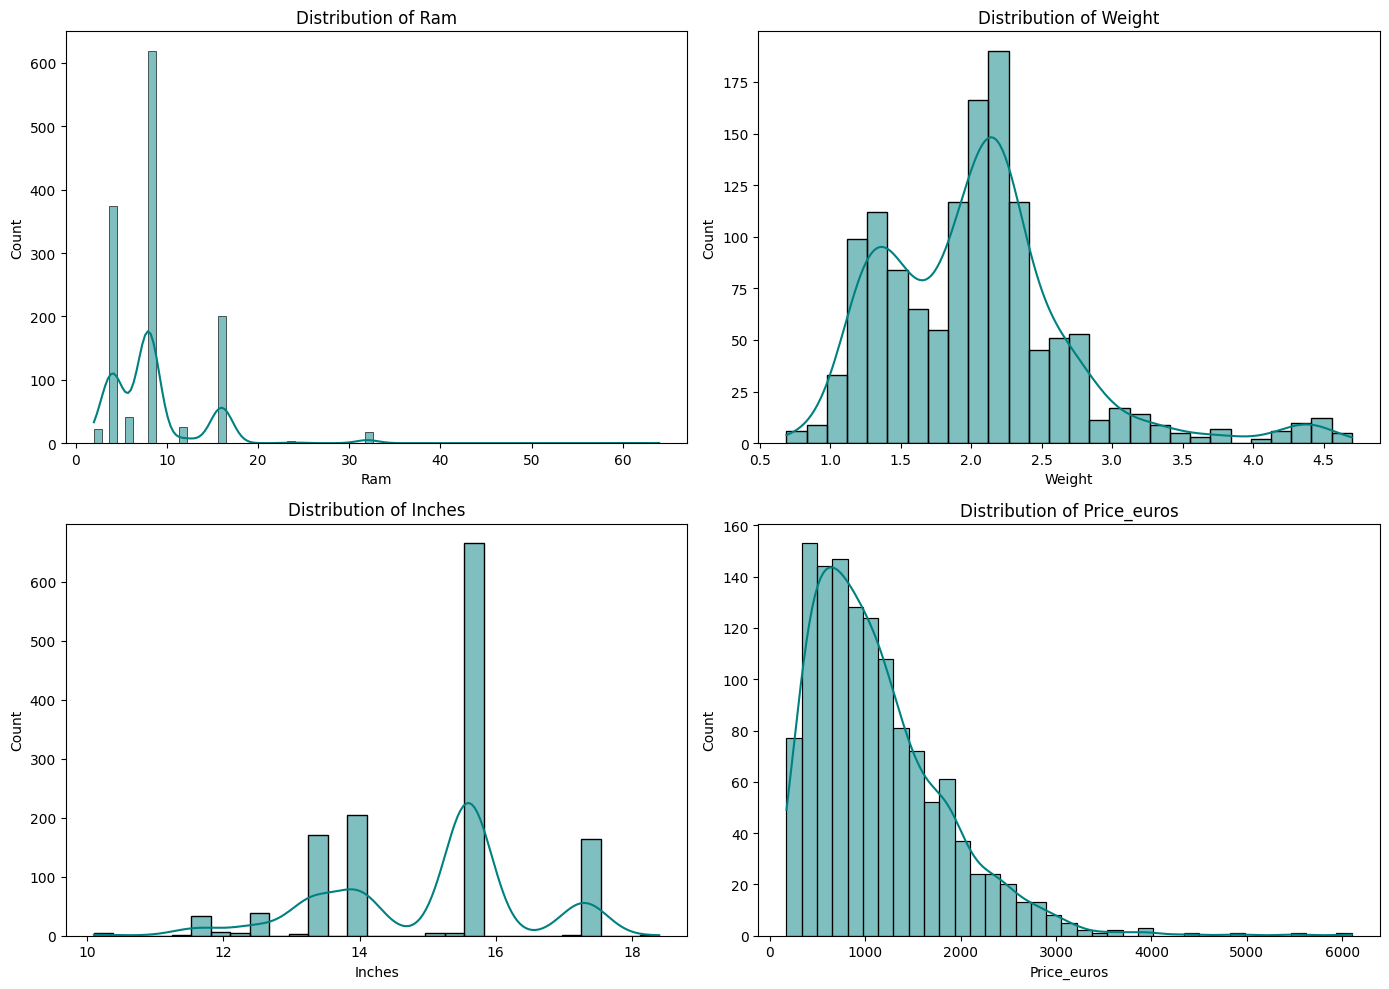

In [ ]:
plt.figure(figsize=(14, 10))

columns = ['Ram', 'Weight', 'Inches', 'Price_euros']

for i, col in enumerate(columns, 1):
    plt.subplot(2, 2, i)
    sns.histplot(
        eda_df[col],
        kde=True,
        color='teal'
    )
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)

plt.tight_layout()
plt.show()


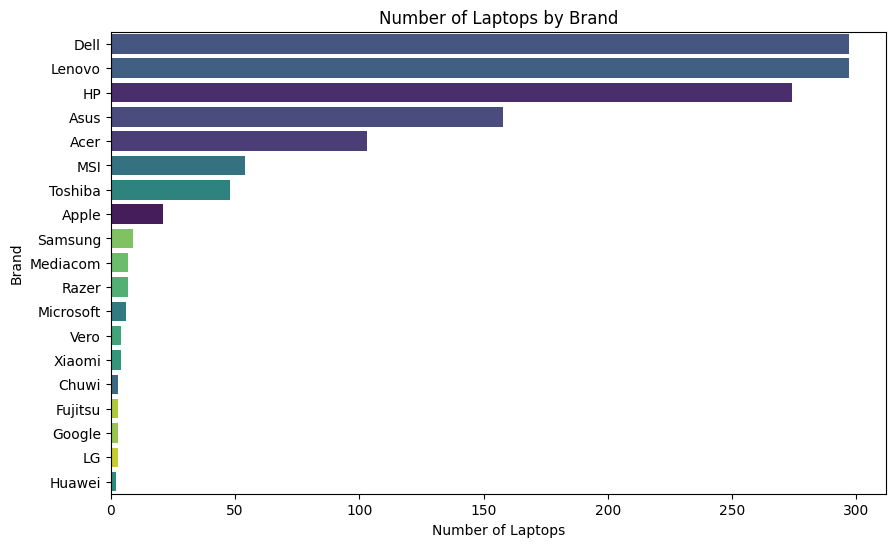

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=eda_df,
    y='Company',
    order=eda_df['Company'].value_counts().index,
    hue='Company',
    palette='viridis',
    legend=False
)

plt.title('Number of Laptops by Brand')
plt.xlabel('Number of Laptops')
plt.ylabel('Brand')
plt.show()


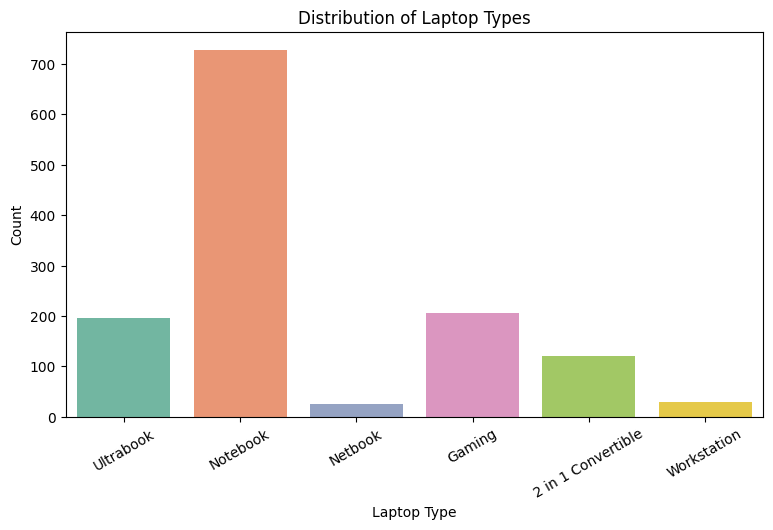

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=eda_df,
    x='TypeName',
    hue='TypeName',
    palette='Set2',
    legend=False
)

plt.title('Distribution of Laptop Types')
plt.xlabel('Laptop Type')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.show()


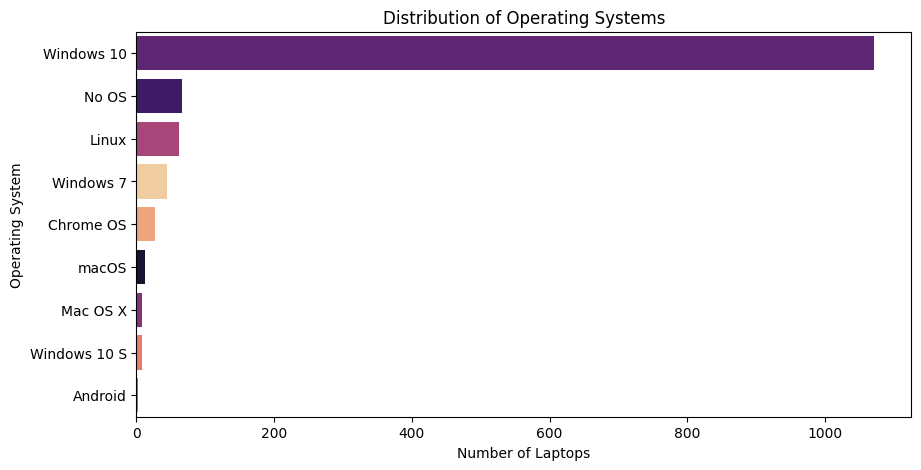

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=eda_df,
    y='OpSys',
    order=eda_df['OpSys'].value_counts().index,
    hue='OpSys',
    palette='magma',
    legend=False
)

plt.title('Distribution of Operating Systems')
plt.xlabel('Number of Laptops')
plt.ylabel('Operating System')
plt.show()


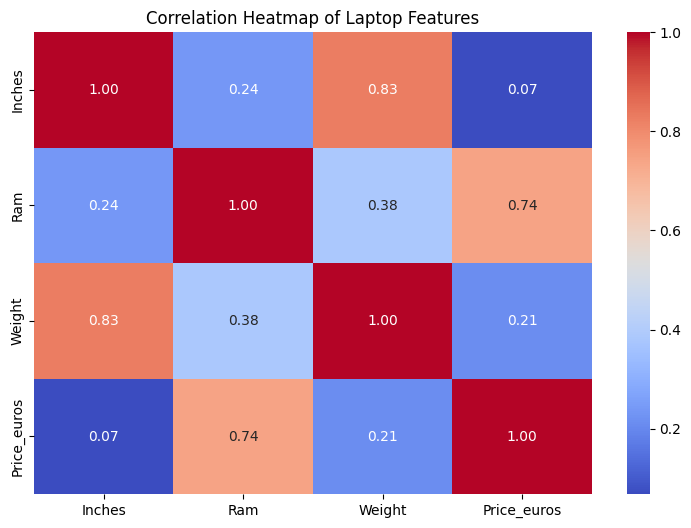

In [ ]:
plt.figure(figsize=(9, 6))

numeric_df = eda_df[
    ['Inches', 'Ram', 'Weight', 'Price_euros']
]

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Laptop Features')
plt.show()


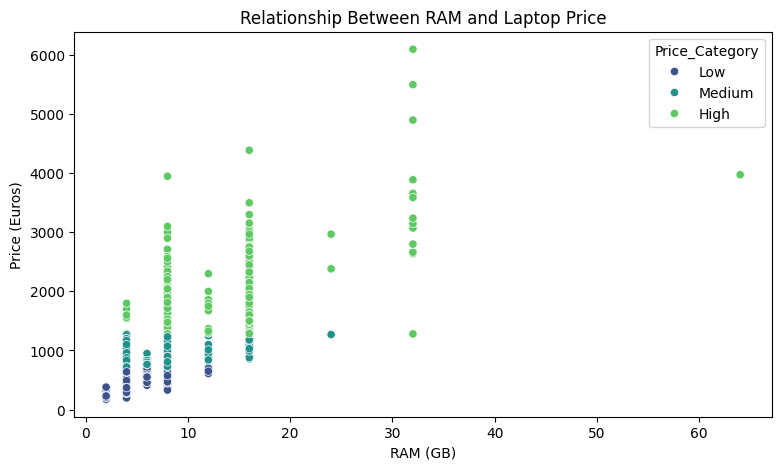

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=eda_df,
    x='Ram',
    y='Price_euros',
    hue='Price_Category',
    palette='viridis'
)

plt.title('Relationship Between RAM and Laptop Price')
plt.xlabel('RAM (GB)')
plt.ylabel('Price (Euros)')
plt.show()


In [ ]:
print("Most frequent laptop brand:")
print(eda_df['Company'].value_counts().head(5))

print("\nCorrelation with laptop price:")
print(
    correlation['Price_euros']
    .sort_values(ascending=False)
)


Most frequent laptop brand:
Company
Dell      297
Lenovo    297
HP        274
Asus      158
Acer      103
Name: count, dtype: int64

Correlation with laptop price:
Price_euros    1.000000
Ram            0.743007
Weight         0.210370
Inches         0.068197
Name: Price_euros, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")


StandardScaler imported successfully!


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")


Feature scaling completed successfully!


In [ ]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("First five rows of scaled data:")
display(X_train_scaled_df.head())

print("\nMean of scaled features:")
print(X_train_scaled_df.mean().round(2).head())

print("\nStandard deviation:")
print(X_train_scaled_df.std().round(2).head())


First five rows of scaled data:


,Inches,Ram,Weight,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,Company_HP,...,Gpu_Nvidia Quadro M620,Gpu_Nvidia Quadro M620M,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,0.421852,-0.848453,0.254434,-0.132583,-0.360766,-0.053734,1.80845,-0.043853,-0.053734,-0.529243,...,-0.069438,-0.030994,-0.153544,-0.229184,-0.08796,-0.222138,0.461561,-0.062077,-0.189170,-0.098437
1,-0.005676,-0.848453,0.071640,-0.132583,-0.360766,-0.053734,1.80845,-0.043853,-0.053734,-0.529243,...,-0.069438,-0.030994,-0.153544,-0.229184,-0.08796,-0.222138,0.461561,-0.062077,-0.189170,-0.098437
2,-1.787041,1.476055,-1.710607,-0.132583,2.771883,-0.053734,-0.55296,-0.043853,-0.053734,-0.529243,...,-0.069438,-0.030994,-0.153544,-0.229184,-0.08796,-0.222138,0.461561,-0.062077,-0.189170,-0.098437
3,1.633180,-0.073617,1.473064,-0.132583,-0.360766,-0.053734,-0.55296,-0.043853,-0.053734,1.889491,...,-0.069438,-0.030994,-0.153544,-0.229184,-0.08796,-0.222138,-2.166562,-0.062077,5.286251,-0.098437
4,1.419417,-0.073617,0.863749,-0.132583,-0.360766,-0.053734,-0.55296,-0.043853,-0.053734,1.889491,...,-0.069438,-0.030994,-0.153544,-0.229184,-0.08796,-0.222138,0.461561,-0.062077,-0.189170,-0.098437



Mean of scaled features:
Inches           0.0
Ram             -0.0
Weight          -0.0
Company_Apple   -0.0
Company_Asus    -0.0
dtype: float64

Standard deviation:
Inches           1.0
Ram              1.0
Weight           1.0
Company_Apple    1.0
Company_Asus     1.0
dtype: float64


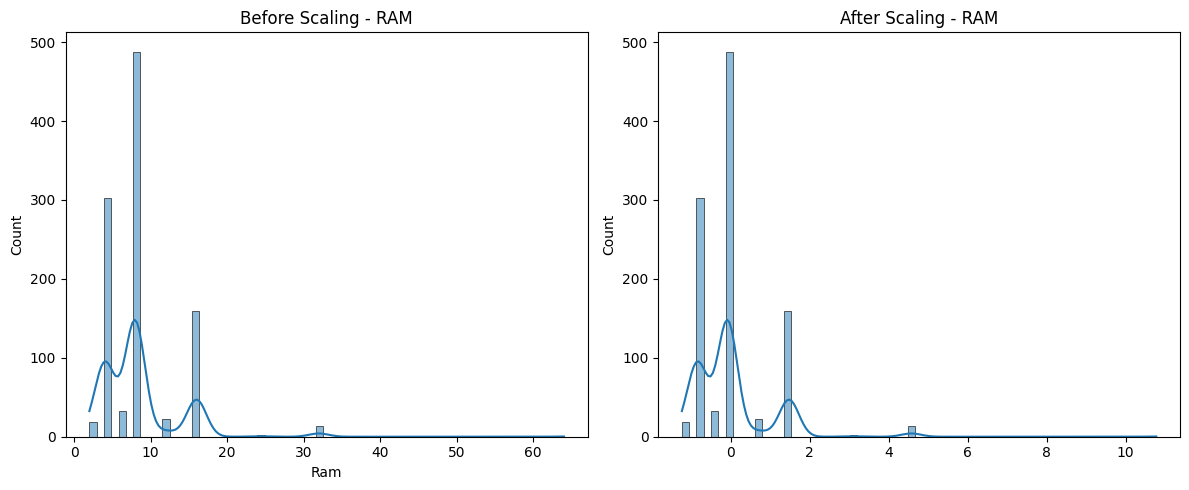

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(X_train['Ram'], kde=True)
plt.title('Before Scaling - RAM')

plt.subplot(1, 2, 2)
sns.histplot(X_train_scaled[:, X_train.columns.get_loc('Ram')], kde=True)
plt.title('After Scaling - RAM')

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.decomposition import PCA

print("PCA imported successfully!")

PCA imported successfully!


In [ ]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print("PCA applied successfully!")


PCA applied successfully!


In [ ]:
print("Original number of features:", X_train_scaled.shape[1])

print("Number of PCA components:", pca.n_components_)

print("Reduced training data shape:", X_train_pca.shape)

print("Reduced testing data shape:", X_test_pca.shape)

Original number of features: 337
Number of PCA components: 209
Reduced training data shape: (1042, 209)
Reduced testing data shape: (261, 209)


In [ ]:
explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:")
print(explained_variance)

print("\nTotal explained variance:")
print(sum(explained_variance))

Explained variance ratio:
[0.01951034 0.01709015 0.01296376 0.01268381 0.01197944 0.01179692
 0.01067864 0.01016528 0.01003768 0.00960141 0.00948224 0.00905761
 0.0087335  0.00851722 0.00820785 0.00801539 0.00795916 0.00780646
 0.00759048 0.00749606 0.00746279 0.00741027 0.00726407 0.00712034
 0.00696733 0.00695937 0.00692704 0.00688731 0.00683009 0.00676121
 0.0066463  0.00656947 0.00652842 0.00652128 0.00647074 0.00644811
 0.006399   0.00639591 0.00639585 0.00637406 0.006352   0.00630028
 0.00625539 0.00621519 0.00617391 0.00612405 0.0060428  0.00592209
 0.00586937 0.00576354 0.00567683 0.00566139 0.00558405 0.00553429
 0.0055006  0.00545829 0.00544941 0.00540397 0.0053324  0.00530581
 0.00523691 0.00517736 0.00514517 0.00512956 0.00509028 0.00506677
 0.00497875 0.00495369 0.00491268 0.00485204 0.00480021 0.00471836
 0.00469787 0.00466017 0.00461213 0.00452444 0.00447719 0.00445689
 0.00438847 0.00436931 0.00431782 0.00429653 0.00424201 0.0041952
 0.0041799  0.00412278 0.00410742 0.0

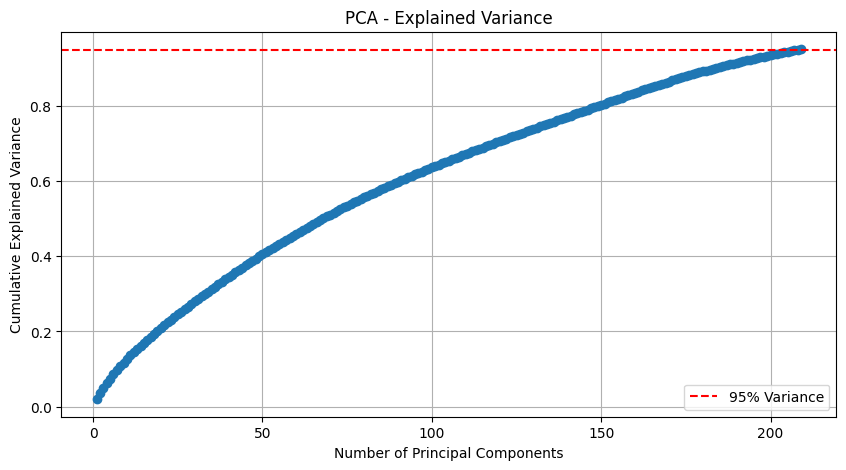

In [ ]:

plt.figure(figsize=(10, 5))

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Explained Variance')
plt.legend()
plt.grid()
plt.show()


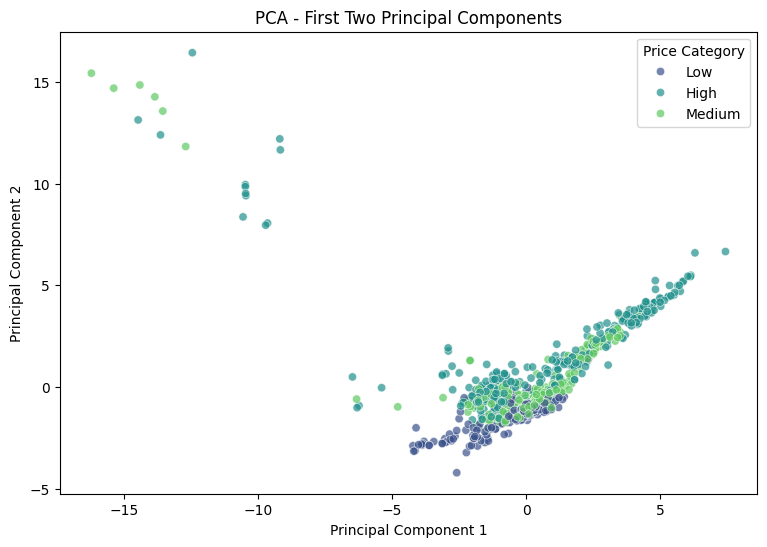

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_train_pca[:, 0],
    y=X_train_pca[:, 1],
    hue=y_train.astype(str),
    palette='viridis',
    alpha=0.7
)

plt.title('PCA - First Two Principal Components')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Price Category')
plt.show()


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score

print("Machine Learning models imported successfully!")


Machine Learning models imported successfully!


In [ ]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_pca, y_train)

dt_predictions = dt_model.predict(X_test_pca)

print("Decision Tree model trained successfully!")

dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

print("Decision Tree Accuracy:", dt_accuracy)


Decision Tree model trained successfully!
Decision Tree Accuracy: 0.7279693486590039


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_pca, y_train)

rf_predictions = rf_model.predict(X_test_pca)

print("Random Forest model trained successfully!")

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)


Random Forest model trained successfully!


In [ ]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train_pca, y_train)

gb_predictions = gb_model.predict(X_test_pca)

print("Gradient Boosting model trained successfully!")

gb_accuracy = accuracy_score(
    y_test,
    gb_predictions
)

print("Gradient Boosting Accuracy:", gb_accuracy)


Gradient Boosting model trained successfully!
Gradient Boosting Accuracy: 0.8084291187739464


In [ ]:
model_results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        dt_accuracy,
        rf_accuracy,
        gb_accuracy
    ]
})

print("Machine Learning Model Results:")
display(model_results)


Machine Learning Model Results:


,Model,Accuracy
0,Decision Tree,0.727969
1,Random Forest,0.808429
2,Gradient Boosting,0.808429


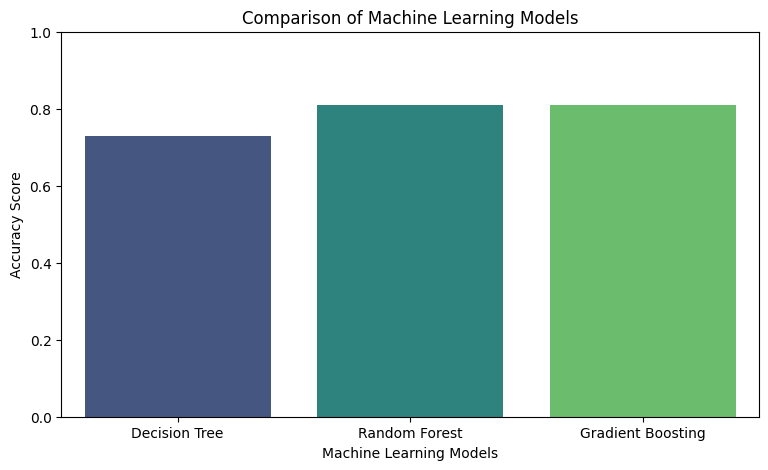

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_results,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy Score')
plt.ylim(0, 1)
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        dt_accuracy,
        rf_accuracy,
        gb_accuracy
    ]
})

comparison = comparison.sort_values(
    by='Accuracy',
    ascending=False
)

In [ ]:
comparison['Accuracy_Percentage'] = (
    comparison['Accuracy'] * 100
).round(2)

display(comparison)


,Model,Accuracy,Accuracy_Percentage
1,Random Forest,0.808429,80.84
2,Gradient Boosting,0.808429,80.84
0,Decision Tree,0.727969,72.80


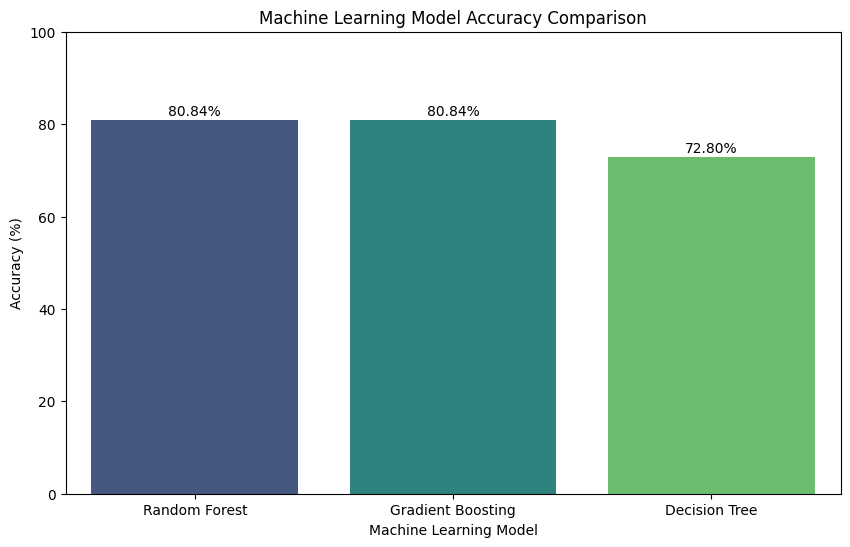

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy_Percentage',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

for i, value in enumerate(comparison['Accuracy_Percentage']):
    plt.text(
        i,
        value + 1,
        f'{value:.2f}%',
        ha='center'
    )

plt.show()


In [ ]:
best_model_name = comparison.iloc[0]['Model']
best_accuracy = comparison.iloc[0]['Accuracy_Percentage']

print("Best Performing Model:", best_model_name)
print("Best Model Accuracy:", best_accuracy, "%")


Best Performing Model: Random Forest
Best Model Accuracy: 80.84 %


In [ ]:
models = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

best_model = models[best_model_name]

print("Selected Model:", best_model)


Selected Model: RandomForestClassifier(random_state=42)


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


              precision    recall  f1-score   support

        High       0.72      0.80      0.76        87
         Low       0.84      0.75      0.79        87
      Medium       0.63      0.63      0.63        87

    accuracy                           0.73       261
   macro avg       0.73      0.73      0.73       261
weighted avg       0.73      0.73      0.73       261



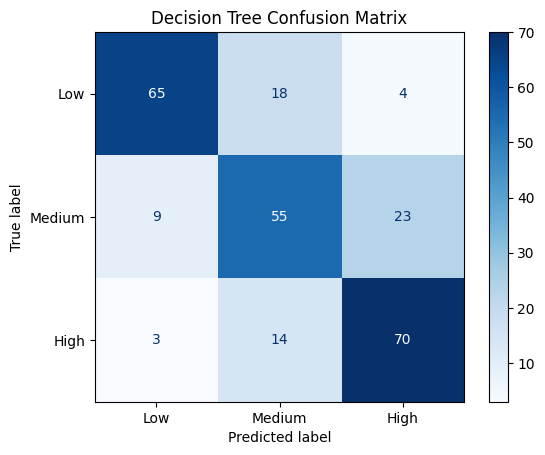

In [ ]:
print(classification_report(
    y_test,
    dt_predictions,
    zero_division=0
))

cm_dt = confusion_matrix(
    y_test,
    dt_predictions,
    labels=['Low', 'Medium', 'High']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Blues')
plt.title("Decision Tree Confusion Matrix")
plt.show()


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.77      0.86      0.81        87
         Low       0.95      0.84      0.89        87
      Medium       0.73      0.72      0.73        87

    accuracy                           0.81       261
   macro avg       0.82      0.81      0.81       261
weighted avg       0.82      0.81      0.81       261



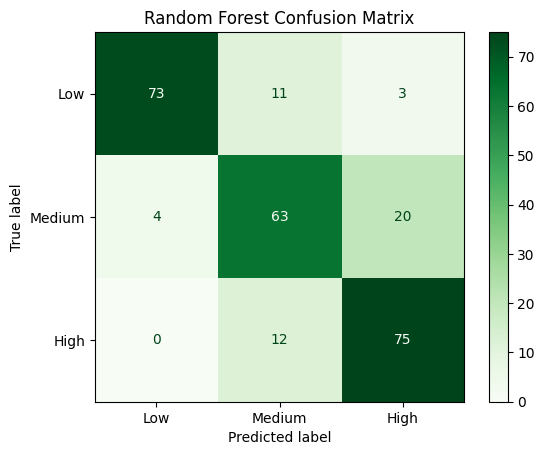

In [ ]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

cm_rf = confusion_matrix(
    y_test,
    rf_predictions,
    labels=['Low', 'Medium', 'High']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Greens')
plt.title("Random Forest Confusion Matrix")
plt.show()


GRADIENT BOOSTING CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.79      0.85      0.82        87
         Low       0.90      0.85      0.88        87
      Medium       0.74      0.72      0.73        87

    accuracy                           0.81       261
   macro avg       0.81      0.81      0.81       261
weighted avg       0.81      0.81      0.81       261



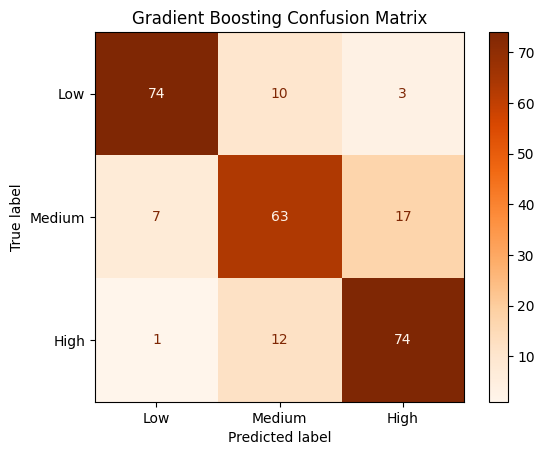

In [ ]:
print("GRADIENT BOOSTING CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    gb_predictions,
    zero_division=0
))

cm_gb = confusion_matrix(
    y_test,
    gb_predictions,
    labels=['Low', 'Medium', 'High']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=['Low', 'Medium', 'High']
)

disp.plot(cmap='Oranges')
plt.title("Gradient Boosting Confusion Matrix")
plt.show()


In [ ]:
evaluation_results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, gb_predictions)
    ],
    'Precision': [
        precision_score(y_test, dt_predictions, average='weighted', zero_division=0),
        precision_score(y_test, rf_predictions, average='weighted', zero_division=0),
        precision_score(y_test, gb_predictions, average='weighted', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, dt_predictions, average='weighted', zero_division=0),
        recall_score(y_test, rf_predictions, average='weighted', zero_division=0),
        recall_score(y_test, gb_predictions, average='weighted', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, dt_predictions, average='weighted', zero_division=0),
        f1_score(y_test, rf_predictions, average='weighted', zero_division=0),
        f1_score(y_test, gb_predictions, average='weighted', zero_division=0)
    ]
})

display(evaluation_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7280,0.7327,0.7280,0.7286
1,Random Forest,0.8084,0.8153,0.8084,0.8098
2,Gradient Boosting,0.8084,0.8103,0.8084,0.8087


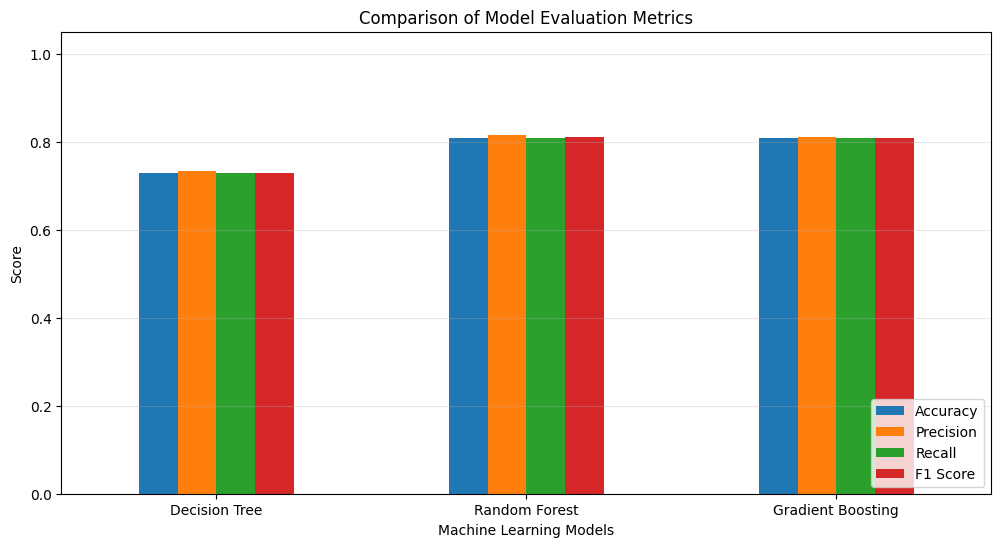

In [ ]:
evaluation_plot = evaluation_results.set_index('Model')

evaluation_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Model Evaluation Metrics')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()


In [ ]:
import joblib

joblib.dump(scaler, 'scaler.pkl')
joblib.dump(pca, 'pca.pkl')
joblib.dump(best_model, 'best_model.pkl')
joblib.dump(X.columns.tolist(), 'feature_columns.pkl')

print("All model files saved successfully!")
print("Best Model:", best_model_name)

All model files saved successfully!
Best Model: Random Forest


In [ ]:
from google.colab import files

files.download('scaler.pkl')
files.download('pca.pkl')
files.download('best_model.pkl')
files.download('feature_columns.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
!pip install -q streamlit

import streamlit as st
import pandas as pd
import joblib

# Load saved model components using relative paths matching how they were saved
scaler = joblib.load('scaler.pkl')
pca = joblib.load('pca.pkl')
model = joblib.load('best_model.pkl')
feature_columns = joblib.load('feature_columns.pkl')

st.title("Laptop Price Category Prediction")
st.write("Enter laptop specifications to predict its price category.")

# User inputs
company = st.selectbox("Company", [
    "Acer", "Apple", "Asus", "Dell", "HP", "Lenovo",
    "MSI", "Toshiba", "Samsung", "Razer", "Other"
])

type_name = st.selectbox("Laptop Type", [
    "Notebook", "Ultrabook", "Gaming", "2 in 1 Convertible",
    "Workstation", "Netbook"
])

inches = st.number_input("Screen Size (inches)", 10.0, 20.0, 15.6)
screen_resolution = st.text_input(
    "Screen Resolution", "1920x1080"
)
cpu = st.text_input("CPU", "Intel Core i5 7200U 2.5GHz")
ram = st.selectbox("RAM", ["4GB", "8GB", "16GB", "32GB"])
memory = st.text_input("Memory", "256GB SSD")
gpu = st.text_input("GPU", "Intel HD Graphics 620")
opsys = st.selectbox("Operating System", [
    "Windows 10", "Windows 7", "macOS", "Linux",
    "No OS", "Chrome OS"
])
weight = st.number_input("Weight (kg)", 0.5, 5.0, 2.0)

if st.button("Predict Price Category"):

    # Prepare input data
    input_data = pd.DataFrame([{
        "Company": company,
        "TypeName": type_name,
        "Inches": inches,
        "ScreenResolution": screen_resolution,
        "Cpu": cpu,
        "Ram": float(ram.replace("GB", "")),
        "Memory": memory,
        "Gpu": gpu,
        "OpSys": opsys,
        "Weight": weight
    }])

    # Convert categorical data to dummy variables
    input_encoded = pd.get_dummies(input_data, dtype=int)

    # Match the training feature columns
    input_encoded = input_encoded.reindex(
        columns=feature_columns, fill_value=0
    )

    # Scale and apply PCA
    input_scaled = scaler.transform(input_encoded)
    input_pca = pca.transform(input_scaled)

    # Predict
    prediction = model.predict(input_pca)[0]

    st.success(f"Predicted Laptop Price Category: {prediction}")

FileNotFoundError: [Errno 2] No such file or directory: 'scaler.pkl'